# HW#1: Extreme Rainfall Deficit in Singapore 

```{admonition} Objectives
:class: tip

This homework will help you gain a better understanding in terms of the ways how to:
* Fit Generalized Extreme Value (GEV) distribution 
* Estimate the return level of extreme rainfall deficit

Happy coding!
```

```{admonition} Submission Guide

Deadline: **Sunday 11:59 pm, 1st November 2026** 
(Note: Late submissions will not be accepted). 

Please upload your solutions to [Canvas](https://canvas.nus.edu.sg/courses/93388/assignments/279688) in a Jupyter Notebook format with the name "Homework1_StudentID.ipynb". Make sure to write down your student ID and full name in the cell below. 

For any questions, feel free to contact Prof. Xiaogang HE ([hexg@nus.edu.sg](mailto:hexg@nus.edu.sg)) or Yifan LU ([yifan_lu@u.nus.edu](mailto:yifan_lu@u.nus.edu)).

```

In [1]:
## Fill your student ID and full name below.

# Student ID:
# Full name:

**Data**:
You will need to use the historical (1981-2020) daily total rainfall at Singapore's Changi station for this homework. 
You can create a DataFrame using Pandas by reading file "../../assets/data/Changi_daily_rainfall.csv".

## Q1: Calculate daily rainfall statistics (10 marks)

Calculate the following statistics for daily rainfall during DJF (**D**ecember-**J**anuary-**F**ebruary): (i) mean, (ii) variance, (iii) skewness, and (iv) kurtosis.

Hint: 
- You can filter the daily rainfall time series for DJF using Pandas' boolean filtering method. Details on filtering values can be found in the [Pandas tutorial](https://xiaoganghe.github.io/python-climate-visuals/chapters/data-analytics/pandas-basic.html).
- DJF spans across two calendar years. Make sure you only include complete DJF seasons. For the period 1981 to 2020, this results in 39 complete DJF seasons, from DJF 1981-1982 to DJF 2019-2020.

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import fsolve
from scipy.stats import genextreme as gev

In [ ]:
rain = pd.read_csv('..\\..\\assets\\data\\Changi_daily_rainfall.csv', index_col = 0, header = 0, parse_dates = True)
display(rain.head(10))

,Daily Rainfall Total (mm)
Date,
1981-01-01,0.0
1981-01-02,0.0
1981-01-03,0.0
1981-01-04,0.0
1981-01-05,0.0
1981-01-06,0.3
1981-01-07,51.4
1981-01-08,0.0
1981-01-09,4.4


In [4]:
# Filter daily rainfall for December-January-February (DJF)
DJF_rain = rain.loc[(rain.index.month < 3) | (rain.index.month > 11)]
# Select the complete DJF periods
DJF_rain = DJF_rain.loc['19811201':'20200301']
# Calculate the following statistics for daily rainfall during DJF: (i) mean; (ii) variance; (iii) skewness; and (iv) kurtosis.
DJF_rain_stats = pd.Series([
                            DJF_rain.mean().values[0], 
                            DJF_rain.var().values[0], 
                            DJF_rain.skew().values[0], 
                            DJF_rain.kurtosis().values[0]],
                            index=['Mean', 'Variance', 'Skewness', 'Kurtosis']
                            )
display(DJF_rain_stats)

Mean          7.203409
Variance    340.698022
Skewness      4.909512
Kurtosis     33.412606
dtype: float64

In [5]:
# Add 'Year' column to denote the year of the days
DJF_rain['Year'] = np.where(DJF_rain.index.month==12, DJF_rain.index.year.values, DJF_rain.index.year.values-1)
# Group by DJF season year
DJF_rain_grouped = DJF_rain.groupby('Year')['Daily Rainfall Total (mm)']

# Compute each statistic explicitly
DJF_stats = pd.DataFrame({
    'mean': DJF_rain_grouped.mean(),
    'variance': DJF_rain_grouped.var(),
    'skew': DJF_rain_grouped.skew(),
    'fisher_kurtosis': DJF_rain_grouped.apply(pd.Series.kurt),
    'pearson_kurtosis': DJF_rain_grouped.apply(pd.Series.kurt) + 3
})

DJF_stats

,mean,variance,skew,fisher_kurtosis,pearson_kurtosis
Year,,,,,
1981,5.803333,177.008865,3.031608,9.601951,12.601951
1982,8.285556,323.570688,3.226329,12.567868,15.567868
1983,12.002198,782.667106,3.819583,16.588514,19.588514
1984,5.197778,133.260220,3.113894,10.226615,13.226615
1985,7.500000,298.638427,3.266719,11.947807,14.947807
1986,11.363333,590.704596,3.260409,12.065640,15.065640
1987,5.147253,137.969409,3.144627,11.282675,14.282675
1988,3.388889,97.620325,3.522151,12.658900,15.658900
1989,3.902222,116.119995,4.447478,22.850849,25.850849


## Q2: Preprocess daily rainfall data (20 marks)

Find the seasonal maximum rainfall deficit for DJF, based on the 30-day centered moving average rainfall deficit.

To do this: 
- Compute the 30-day centered moving average of daily rainfall. (10 marks)
- Calculate the daily rainfall deficit by subtracting the 30-day moving average rainfall from the mean rainfall calculated in Q1. (5 marks)
- For each DJF season, take the maximum deficit (one value per season). This yields 39 seasonal maxima. (5 marks)

In [6]:
DJF_rain

,Daily Rainfall Total (mm),Year
Date,,
1981-12-01,18.3,1981
1981-12-02,7.2,1981
1981-12-03,0.0,1981
1981-12-04,50.9,1981
1981-12-05,5.7,1981
...,...,...
2020-02-25,0.0,2019
2020-02-26,0.0,2019
2020-02-27,0.0,2019


In [7]:
# Calculate the 30-day moving average for each year
DJF_rain_a = DJF_rain.groupby(['Year']).rolling(30, center=True).mean()
DJF_rain_a = DJF_rain_a.dropna(subset='Daily Rainfall Total (mm)')
DJF_rain_a.rename(columns={'Daily Rainfall Total (mm)': '30-day Moving Average Rainfall (mm)'}, inplace=True)

In [8]:
# Method 1 — Single mean across all DJF data
DJF_rain_def1 = DJF_rain['Daily Rainfall Total (mm)'].mean() - DJF_rain_a.iloc[:, 0]
DJF_rain_def1 = DJF_rain_def1.to_frame('30-day Moving Average Rainfall Deficit (mm)')

# Method 2 — Year-specific mean from DJF_stats
DJF_rain_def2 = DJF_stats['mean'].sub(DJF_rain_a.iloc[:, 0], level='Year')
DJF_rain_def2 = DJF_rain_def2.to_frame('30-day Moving Average Rainfall Deficit (mm)')

# Change method here
DJF_rain_def = DJF_rain_def1
display(DJF_rain_def)

30-day Moving Average Rainfall Deficit (mm)
Year Date                                                   
1981 1981-12-16                                    -5.286591
     1981-12-17                                    -5.099924
     1981-12-18                                    -5.616591
     1981-12-19                                    -6.663258
     1981-12-20                                    -4.976591
...                                                      ...
2019 2020-02-11                                     3.170076
     2020-02-12                                     4.436742
     2020-02-13                                     4.436742
     2020-02-14                                     5.036742
     2020-02-15                                     5.036742

[2389 rows x 1 columns]

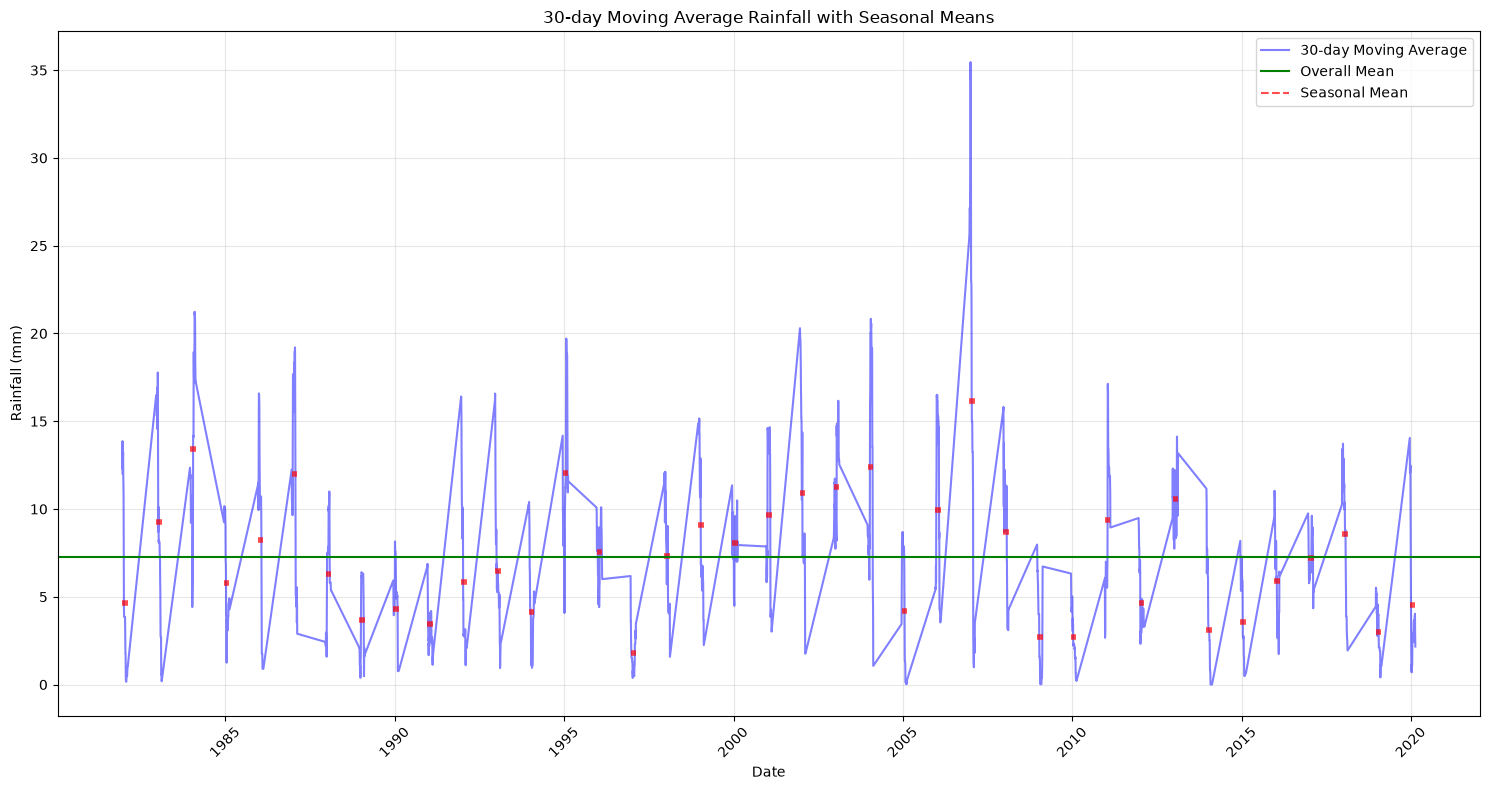

In [9]:
# Create a figure with appropriate size
plt.figure(figsize=(15, 8))

# Plot the original time series
plt.plot(DJF_rain_a.index.get_level_values('Date'), 
         DJF_rain_a['30-day Moving Average Rainfall (mm)'], 
         'b-', alpha=0.5, label='30-day Moving Average')

# Calculate and plot annual mean
annual_mean = DJF_rain_a.groupby(level='Year')['30-day Moving Average Rainfall (mm)'].mean()
for year in annual_mean.index:
    year_data = DJF_rain_a.xs(year, level='Year')
    start_time = year_data.index[0]
    end_time = year_data.index[-1]
    plt.hlines(y=annual_mean[year], 
               xmin=start_time,
               xmax=end_time,
               color='r', linestyle='--', alpha=0.7, linewidth=4)

# Calculate the overall mean
overall_mean = DJF_rain_a['30-day Moving Average Rainfall (mm)'].mean()
plt.axhline(y=overall_mean, color='g', linestyle='-', label='Overall Mean')

plt.title('30-day Moving Average Rainfall with Seasonal Means')
plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')

# Create custom legend with correct line styles
from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='b', linestyle='-', alpha=0.5),
    Line2D([0], [0], color='g', linestyle='-'),
    Line2D([0], [0], color='r', linestyle='--', alpha=0.7)
]
plt.legend(custom_lines, ['30-day Moving Average', 'Overall Mean', 'Seasonal Mean'])

plt.grid(True, alpha=0.3)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Calculate the maximum deficit for each year
DJF_max_def = pd.DataFrame(DJF_rain_def['30-day Moving Average Rainfall Deficit (mm)'].groupby('Year').max())
DJF_max_def.columns = ['DJF Maximum Rainfall Deficit (mm)']
DJF_max_def

,DJF Maximum Rainfall Deficit (mm)
Year,
1981,7.040076
1982,7.016742
1983,2.786742
1984,5.956742
1985,6.306742
1986,4.306742
1987,5.616742
1988,6.816742
1989,6.440076


## Q3: Fit the GEV distribution (20 marks)

Fit a GEV distribution to the time series of seasonal maximum rainfall deficits. To do this, estimate the GEV parameters using (i) Maximum Likelihood and (ii) L-Moments, respectively. (Details on fitting a GEV distribution can be found in the [Scipy tutorial](https://xiaoganghe.github.io/python-climate-visuals/chapters/data-analytics/scipy-basic.html))

In [11]:
# Fit the distribution using MLE
cMLE, locMLE, scaleMLE = gev.fit(DJF_max_def, method = "MLE")
MLEGEV = gev(cMLE, loc = locMLE, scale = scaleMLE) 

In [12]:
# Calculate L-moments based on samples
def samlmom3(sample):
    """
    samlmom3 returns the first three L-moments of samples
    sample is the 1-d array
    n is the total number of the samples, j is the j_th sample
    """
    n = len(sample)
    sample = np.sort(sample.reshape(n))[::-1]
    b0 = np.mean(sample)
    b1 = np.array([(n - j - 1) * sample[j] / n / (n - 1)
                   for j in range(n)]).sum()
    b2 = np.array([(n - j - 1) * (n - j - 2) * sample[j] / n / (n - 1) / (n - 2)
                   for j in range(n - 1)]).sum()
    lmom1 = b0
    lmom2 = 2 * b1 - b0
    lmom3 = 6 * (b2 - b1) + b0

    return lmom1, lmom2, lmom3

def pargev_fsolve(lmom):
    """
    pargev_fsolve estimates the parameters of the Generalized Extreme Value 
    distribution given the L-moments of samples
    """
    lmom_ratios = [lmom[0], lmom[1], lmom[2] / lmom[1]]
    f = lambda x, t: 2 * (1 - 3**(-x)) / (1 - 2**(-x)) - 3 - t
    G = fsolve(f, 0.01, lmom_ratios[2])[0]
    para3 = G
    GAM = math.gamma(1 + G)
    para2 = lmom_ratios[1] * G / (GAM * (1 - 2**-G))
    para1 = lmom_ratios[0] - para2 * (1 - GAM) / G
    return para1, para2, para3

In [13]:
# Fit the distribution using LMM
LMM = samlmom3(DJF_max_def.values)
locLMM, scaleLMM, cLMM = pargev_fsolve(LMM)
LMMGEV = gev(cLMM, loc=locLMM, scale=scaleLMM) 

In [14]:
print('Parameters fitted by Maximum Likelihood: shape={:.3f}, loc={:.3f}, scale={:.3f}\n'
      .format(cMLE, locMLE, scaleMLE,))
print('Parameters fitted by L-Moments: shape={:.3f}, loc={:.3f}, scale={:.3f}\n'
      .format(cLMM, locLMM, scaleLMM))

Parameters fitted by Maximum Likelihood: shape=1.082, loc=5.252, scale=2.104

Parameters fitted by L-Moments: shape=0.945, loc=5.164, scale=2.052



## Q4: Estimate the return level of the extreme events (20 marks)

Using the GEV parameters estimated with L-Moments in Q3, estimate the rainfall deficit for events with return periods of 10 years, 50 years, 100 years, and 1000 years.

In [15]:
T = np.arange(2, 1001)
rainDef_lmm = LMMGEV.ppf(1 - 1.0 / T)
rainDef_lmm = pd.DataFrame(rainDef_lmm, index = T, 
                      columns = ["DJF Maximum Rainfall Deficit (mm)"])
rainDef_lmm.index.name = "Return period"

display(rainDef_lmm.loc[[10, 50, 100, 1000]])

,DJF Maximum Rainfall Deficit (mm)
Return period,
10,7.076497
50,7.281076
100,7.307344
1000,7.332279


## Q5: Test the goodness-of-fit (20 marks)

In this task, you will compare how different distributions fit the same dataset and interpret the results using statistical analyses. 
- Repeat the distribution fitting as in Q3, but this time using a [normal distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html) and the Maximum Likelihood method. (5 marks)
- Use the Kolmogorov-Smirnov (KS) test to evaluate the goodness-of-fit for both the normal distribution and the GEV distribution you obtained in Q3. (Details on the KS test can be found in the [Scipy tutorial](https://xiaoganghe.github.io/python-climate-visuals/chapters/data-analytics/scipy-basic.html)) (5 marks)
- Based on the KS test results, discuss how well each distribution (Normal and GEV) fits the data. (10 marks)

**Bonus (5 marks):**
- Plot the CDF (Cumulative Distribution Function) to visually compare the fitted normal distribution, the GEV distribution, and the empirical distribution derived from the data. Compare the behavior of the two distributions at different return periods. Are the KS statistic results consistent with your observations from the CDF plot?


Hint: You can recycle the empirical distribution estimation and CDF plotting code from the [Scipy tutorial](https://xiaoganghe.github.io/python-climate-visuals/chapters/data-analytics/scipy-basic.html).

In [16]:
# Fit the normal distribution using MLE
from scipy.stats import norm
locMLE, scaleMLE = norm.fit(DJF_max_def, method = "MLE")
MLEnorm = norm(loc = locMLE, scale = scaleMLE) 

In [17]:
from scipy.stats import kstest
GEVKS = kstest(DJF_max_def["DJF Maximum Rainfall Deficit (mm)"], MLEGEV.cdf)
print('Goodness-of-fit for GEV distribution: statistic is {:.3f}, pvalue is {:.3f}'.format(GEVKS.statistic, GEVKS.pvalue))
NORMKS = kstest(DJF_max_def["DJF Maximum Rainfall Deficit (mm)"], MLEnorm.cdf)
print('Goodness-of-fit for Normal distribution: statistic is {:.3f}, pvalue is {:.3f}'.format(NORMKS.statistic, NORMKS.pvalue))

Goodness-of-fit for GEV distribution: statistic is 0.077, pvalue is 0.961
Goodness-of-fit for Normal distribution: statistic is 0.164, pvalue is 0.217


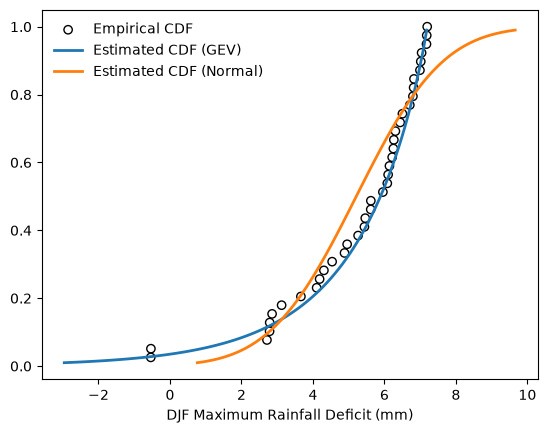

In [18]:
# Plot empirical CDF
plt.scatter(DJF_max_def.sort_values(by = ["DJF Maximum Rainfall Deficit (mm)"]),
            np.arange(1, DJF_max_def.size+1, dtype=float)/DJF_max_def.size,
            color = 'k', facecolors='none', label='Empirical CDF')

# Plot estimated CDF based on maximum likelihood method
bins = np.linspace(MLEGEV.ppf(0.01), MLEGEV.ppf(0.99), 100)
plt.plot(bins, MLEGEV.cdf(bins), 
        lw=2, label='Estimated CDF (GEV)')
# Plot estimated CDF of the fitted normal distribution
bins = np.linspace(MLEnorm.ppf(0.01), MLEnorm.ppf(0.99), 100)
plt.plot(bins, MLEnorm.cdf(bins), 
         lw=2, label='Estimated CDF (Normal)')

plt.xlabel("DJF Maximum Rainfall Deficit (mm)")
plt.legend(loc='best', frameon=False)
plt.show()

GEV distribution describes the data better than the normal distribution. 
The Kolmogorov-Smirnov test confirms that the GEV distribution fits the data better than the normal distribution, as indicated by a lower KS statistic and a higher p-value.
The CDF plot provides a visual confirmation of these findings. Especially, the normal distribution overestimates the probability of occurrence for moderate rainfall deficits (around 4-6 mm).
When we move towards longer return periods (more extreme events), the two curves diverge, with GEV distribution providing a better fit.

## Q6: Sensitivity analysis of averaging period (10 marks)

The rainfall deficit in Q2 was calculated using a 30-day centered moving average. The choice of averaging period can affect the magnitude and timing of identified extreme events.

Using the same DJF rainfall data:
- Calculate a 7-day centered moving average of daily rainfall and the corresponding daily rainfall deficit using the mean rainfall from Q1. (3 marks)
- For each DJF season, calculate the maximum rainfall deficit based on the 7-day moving average and compare it with the 30-day maximum obtained in Q2. (3 marks)
- Create a scatter plot comparing the 7-day and 30-day seasonal maximum deficits, with a 1:1 reference line. (2 marks)
- Identify the DJF season with the largest difference between the 7-day and 30-day maximum deficits. Briefly explain why changing the averaging period can change the magnitude of an extreme rainfall deficit. (2 marks)

In [19]:
# Calculate the 7-day centered moving average separately for each DJF season
DJF_rain_7d = (
    DJF_rain.groupby('Year')
    .rolling(window=7, center=True)
    .mean()
)

# Remove NaN values at the boundaries of each season
DJF_rain_7d = DJF_rain_7d.dropna(
    subset=['Daily Rainfall Total (mm)']
)

# Rename the column
DJF_rain_7d.rename(
    columns={
        'Daily Rainfall Total (mm)': 
        '7-day Moving Average Rainfall (mm)'
    },
    inplace=True
)

# Calculate the daily rainfall deficit using the Q1 mean
DJF_mean = DJF_rain['Daily Rainfall Total (mm)'].mean()

DJF_rain_def_7d = (
    DJF_mean -
    DJF_rain_7d['7-day Moving Average Rainfall (mm)']
).to_frame('7-day Moving Average Rainfall Deficit (mm)')

display(DJF_rain_def_7d)

7-day Moving Average Rainfall Deficit (mm)
Year Date                                                  
1981 1981-12-04                                   -5.053734
     1981-12-05                                   -3.339448
     1981-12-06                                   -2.310877
     1981-12-07                                   -7.596591
     1981-12-08                                   -0.953734
...                                                     ...
2019 2020-02-22                                    3.631981
     2020-02-23                                    3.717695
     2020-02-24                                    4.231981
     2020-02-25                                    6.489123
     2020-02-26                                    6.546266

[3286 rows x 1 columns]

In [20]:
# Calculate the seasonal maximum deficit using the 7-day moving average
DJF_max_def_7d = (
    DJF_rain_def_7d
    .groupby(level='Year')
    .max()
)

DJF_max_def_7d.columns = [
    '7-day Maximum Rainfall Deficit (mm)'
]

# Combine the 7-day and 30-day seasonal maximum deficits
comparison = DJF_max_def_7d.join(DJF_max_def)

comparison.columns = [
    '7-day Maximum Deficit (mm)',
    '30-day Maximum Deficit (mm)'
]

# Calculate the difference between the two averaging periods
comparison['Difference (7-day - 30-day)'] = (
    comparison['7-day Maximum Deficit (mm)'] -
    comparison['30-day Maximum Deficit (mm)']
)

display(comparison.round(3).head(10))

,7-day Maximum Deficit (mm),30-day Maximum Deficit (mm),Difference (7-day - 30-day)
Year,,,
1981,7.203,7.040,0.163
1982,7.203,7.017,0.187
1983,7.203,2.787,4.417
1984,7.203,5.957,1.247
1985,7.203,6.307,0.897
1986,7.203,4.307,2.897
1987,7.203,5.617,1.587
1988,7.203,6.817,0.387
1989,7.203,6.440,0.763


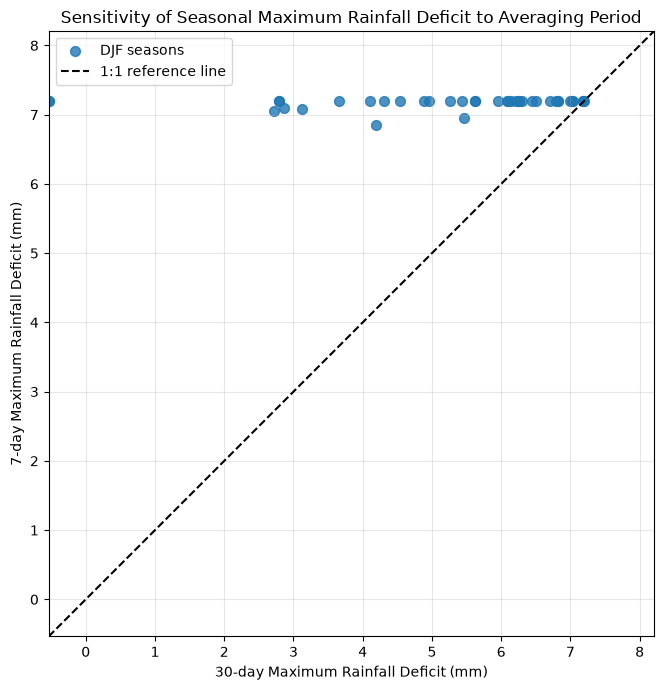

In [21]:
# Create scatter plot
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    comparison['30-day Maximum Deficit (mm)'],
    comparison['7-day Maximum Deficit (mm)'],
    s=50,
    alpha=0.8,
    label='DJF seasons'
)

# Calculate limits for the 1:1 reference line
lower = min(
    comparison['30-day Maximum Deficit (mm)'].min(),
    comparison['7-day Maximum Deficit (mm)'].min()
)

upper = max(
    comparison['30-day Maximum Deficit (mm)'].max(),
    comparison['7-day Maximum Deficit (mm)'].max()
) + 1

# Plot the 1:1 reference line
ax.plot(
    [lower, upper],
    [lower, upper],
    'k--',
    linewidth=1.5,
    label='1:1 reference line'
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect('equal', adjustable='box')

ax.set_xlabel('30-day Maximum Rainfall Deficit (mm)')
ax.set_ylabel('7-day Maximum Rainfall Deficit (mm)')
ax.set_title('Sensitivity of Seasonal Maximum Rainfall Deficit to Averaging Period')

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Identify the DJF season with the largest absolute difference
comparison['Absolute Difference (mm)'] = comparison['Difference (7-day - 30-day)'].abs()
largest_year = comparison['Absolute Difference (mm)'].idxmax()

largest_result = comparison.loc[largest_year]

print(f"Largest difference occurs in DJF {largest_year}-{largest_year+1}")

print(f"7-day maximum deficit:  "
      f"{largest_result['7-day Maximum Deficit (mm)']:.3f} mm")

print(f"30-day maximum deficit: "
      f"{largest_result['30-day Maximum Deficit (mm)']:.3f} mm")

print(f"Absolute difference: "
      f"{largest_result['Absolute Difference (mm)']:.3f} mm")

Largest difference occurs in DJF 2012-2013
7-day maximum deficit:  7.203 mm
30-day maximum deficit: -0.537 mm
Absolute difference: 7.740 mm


The choice of averaging period influences the magnitude of identified extreme rainfall deficits. A shorter averaging period (7 days) is more sensitive to short-term rainfall fluctuations and can capture brief dry spells, potentially resulting in larger maximum rainfall deficits. This is particularly evident in seasons with seven consecutive days of no rainfall, during which the 7-day moving average reaches zero and the maximum deficit reaches 7.203 mm. In contrast, a longer averaging period (30 days) smooths out short-term variations by incorporating rainfall over a longer period, potentially reducing the magnitude of identified extreme deficits. Therefore, the estimated magnitude of extreme rainfall deficits depends on the selected averaging period.